# Preliminary OOD Analysis: Real-World Animals in a Pokémon Classifier

**AM-2k foreground images · 1,800 samples · 20 animal categories**

This notebook summarizes our initial experiment using a Pokémon image classifier on real-world animal images. We first examine overall prediction behavior, then identify which animal categories and Pokémon labels account for the **high-confidence cases**.

> **Scope:** Exploratory analysis of the **FG (foreground) images only**. These results describe the classifier’s predictions; they do not explain their causes yet.

## 1. Summary

Most FG animal images produce **low top-1 confidence** and **relatively high prediction entropy**. However, a small number receive very confident Pokémon predictions.

| Key result | Observation |
|:---|---:|
| Animal images analyzed | **1,800** |
| Animal categories | **20** |
| High-confidence threshold | **Top-1 confidence ≥ 70%** |
| High-confidence images | **39 / 1,800 (2.17%)** |
| Animal categories represented in these 39 images | **10** |
| Predicted Pokémon labels represented | **7** |

The high-confidence cases are **concentrated in a few animal–Pokémon pairs**, particularly **cattle → Bouffalant (17 images)** and **antelope → Sawsbuck (7 images)**.

**Question for the next stage:** Why do certain images within these animal categories receive such high confidence, while most images do not?

## 2. Dataset and model

| Item | Description |
|:---|:---|
| **Animal dataset** | [AM-2k — Google Drive](https://drive.google.com/drive/folders/16WSQY7gtprUykZshbOms_pk07WN0C0Fy) |
| **Dataset split** | Training set: **1,800 original animal images**, covering **20 categories** |
| **Input used here** | **FG images**: extracted foregrounds, rather than the original natural-background images |
| **FG preparation** | Foregrounds generated using a closed-form matting method; extraction artifacts may remain |
| **Classifier** | [Pokémon image classifier (Hugging Face)](https://huggingface.co/imzynoxprince/pokemons-image-classifier-gen1-gen9) |
| **Model** | Vision Transformer (ViT), **1,028 Pokémon output labels** in the loaded checkpoint |
| **Prediction outputs** | Top predicted Pokémon, confidence, normalized entropy, second prediction, top-2 margin |

**Important:** The model is a *closed-set classifier*: it always predicts a Pokémon label, even for an animal photograph. A high softmax score does **not** mean the image is actually a Pokémon, nor does a low score mean the model explicitly detected OOD.

**Dataset citation:** Li, J., Zhang, J., Maybank, S. J., & Tao, D. (2021). *Bridging Composite and Real: Towards End-to-end Deep Image Matting*. IJCV. [Paper](https://arxiv.org/abs/2010.16188) · [Repository](https://github.com/JizhiziLi/GFM).

## 3. Measures and visualization methods

| Measure / visualization | Purpose |
|:---|:---|
| **Top-1 confidence** | Highest Pokémon softmax probability for an input image; indicates how strongly the model favors its first choice. |
| **Normalized entropy** | Summarizes uncertainty over all 1,028 Pokémon classes; higher values indicate a more spread-out distribution. |
| **Top-2 margin** | Difference between the two highest predicted probabilities. |
| **Histogram** | Shows how confidence and entropy are distributed over all FG animal images. |
| **Scatter plot** | Shows the relationship between confidence and entropy for each image. |
| **Box plot** | Compares confidence spread and medians across the 20 animal categories. |
| **High-confidence rate bar chart** | Compares the proportion of images with confidence ≥ 70% in each animal category. |
| **Prediction-frequency heatmap** | Shows which Pokémon labels are assigned to high-confidence animal images. |

The **70% cutoff** is a convenient *exploratory screening threshold*, not a validated OOD detection threshold.

## 4. Global prediction behavior

### 4.1 Top-1 confidence distribution

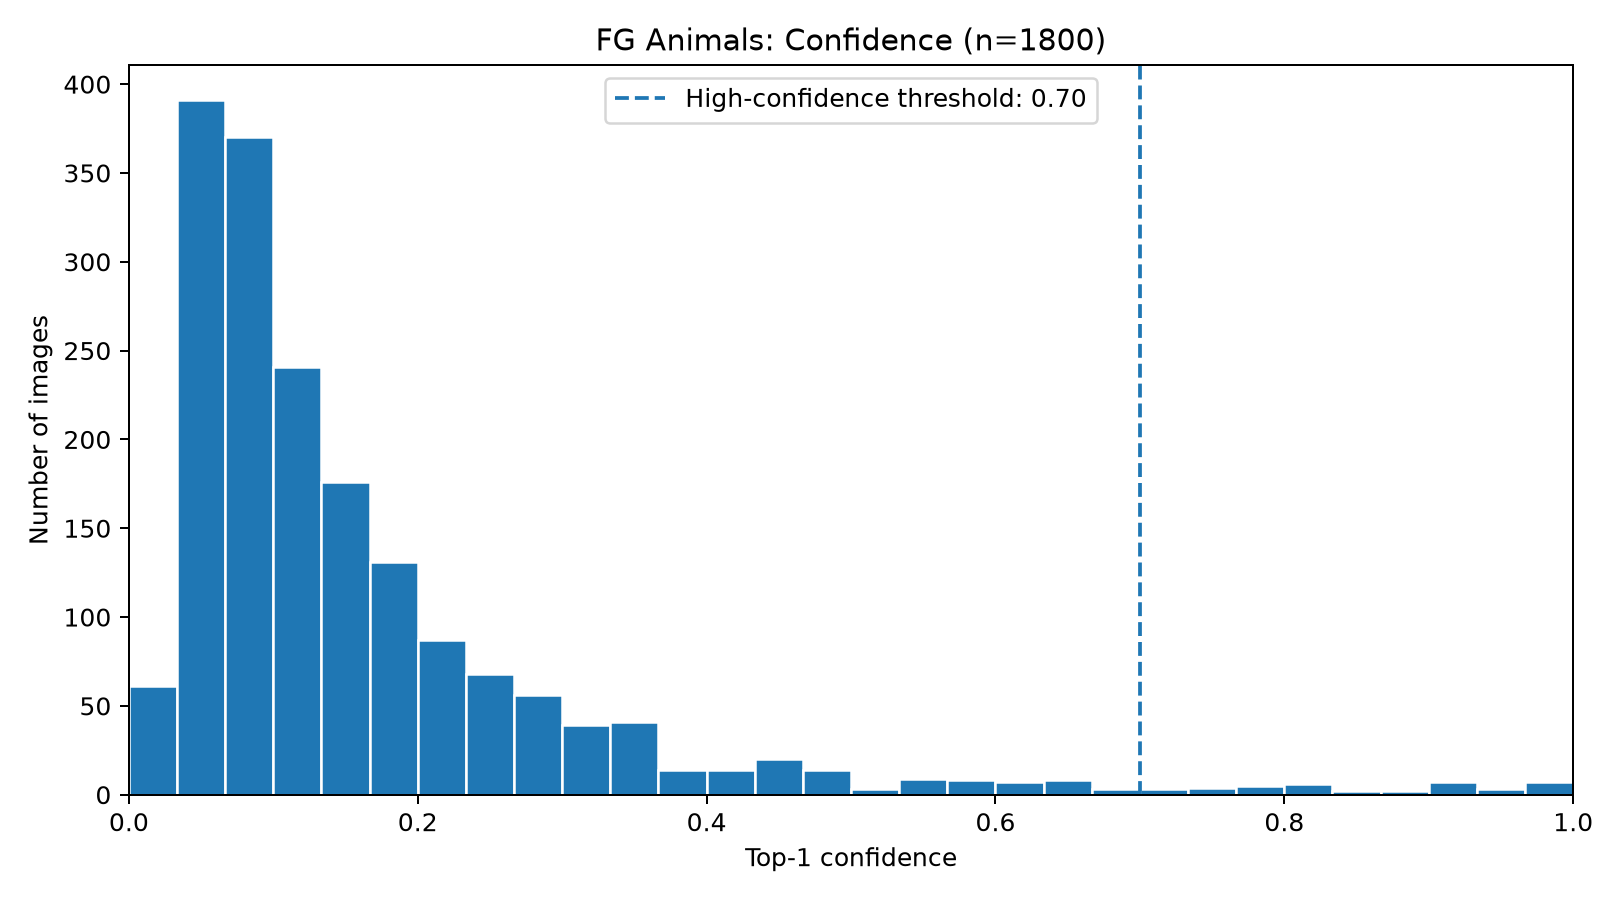

*Figure 1. Top-1 confidence for 1,800 FG animal images. Dashed line: 70% exploratory threshold.*

**Observation:** Most images have low top-1 confidence, concentrated around **0.05–0.20**. A small right-hand tail reaches values close to 1.0; only **39 images (2.17%)** reach 70% or higher.

**Why it matters:** We can focus on these rare high-confidence cases without assuming that most OOD inputs are confidently misclassified.

### 4.2 Normalized entropy distribution

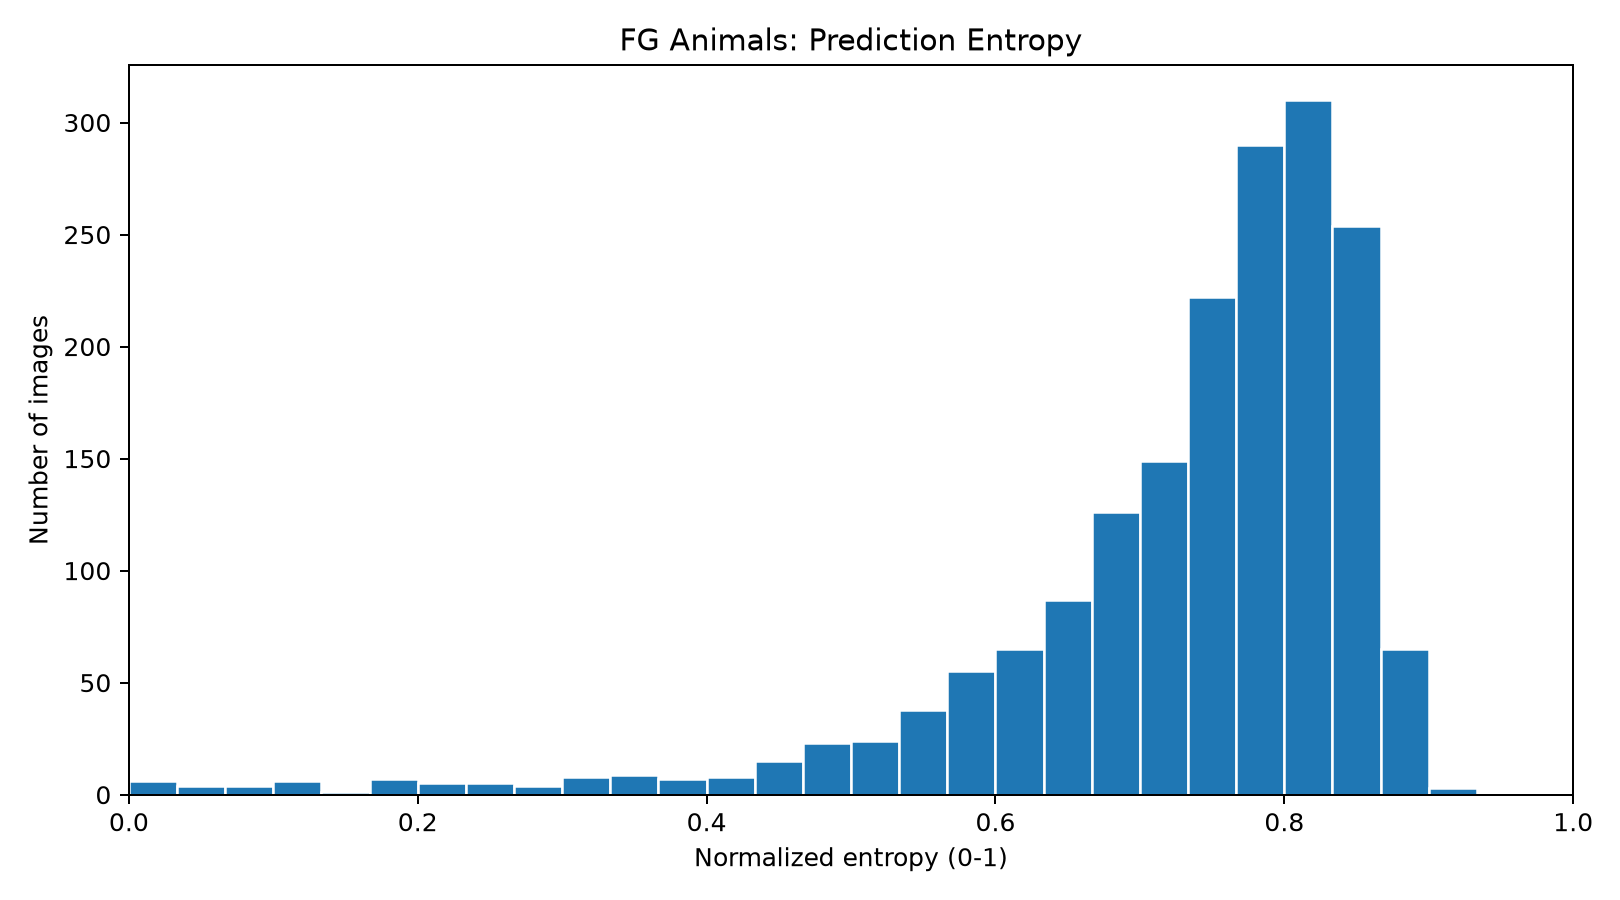

*Figure 2. Normalized entropy of the Pokémon prediction distribution for FG animal images.*

**Observation:** Entropy is generally high, with many values around **0.70–0.85**. The model often spreads probability across several Pokémon labels, although a smaller subset shows low entropy.

### 4.3 Confidence versus entropy

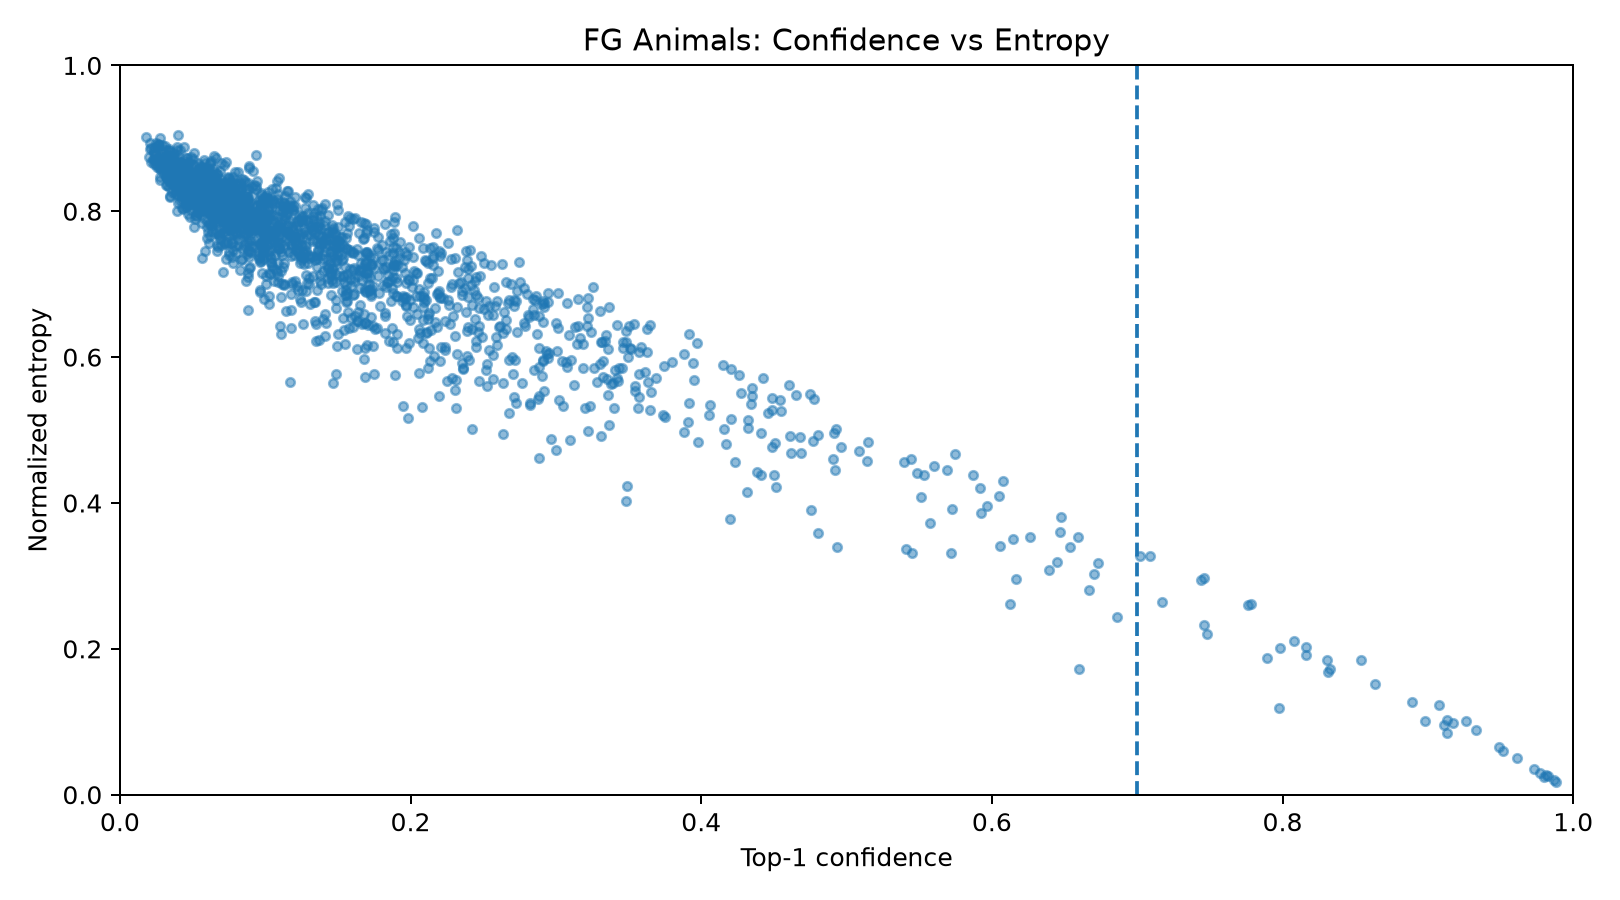

*Figure 3. Relationship between top-1 confidence and normalized entropy; one point per image.*

**Observation:** Higher confidence generally accompanies lower entropy. These measures come from the same softmax output, so their inverse relationship is **not itself a separate discovery**.

**Use of this plot:** Locate the relatively few animal inputs in the **high-confidence / low-entropy** region (bottom right).

## 5. Differences across animal categories

### 5.1 Confidence by animal category

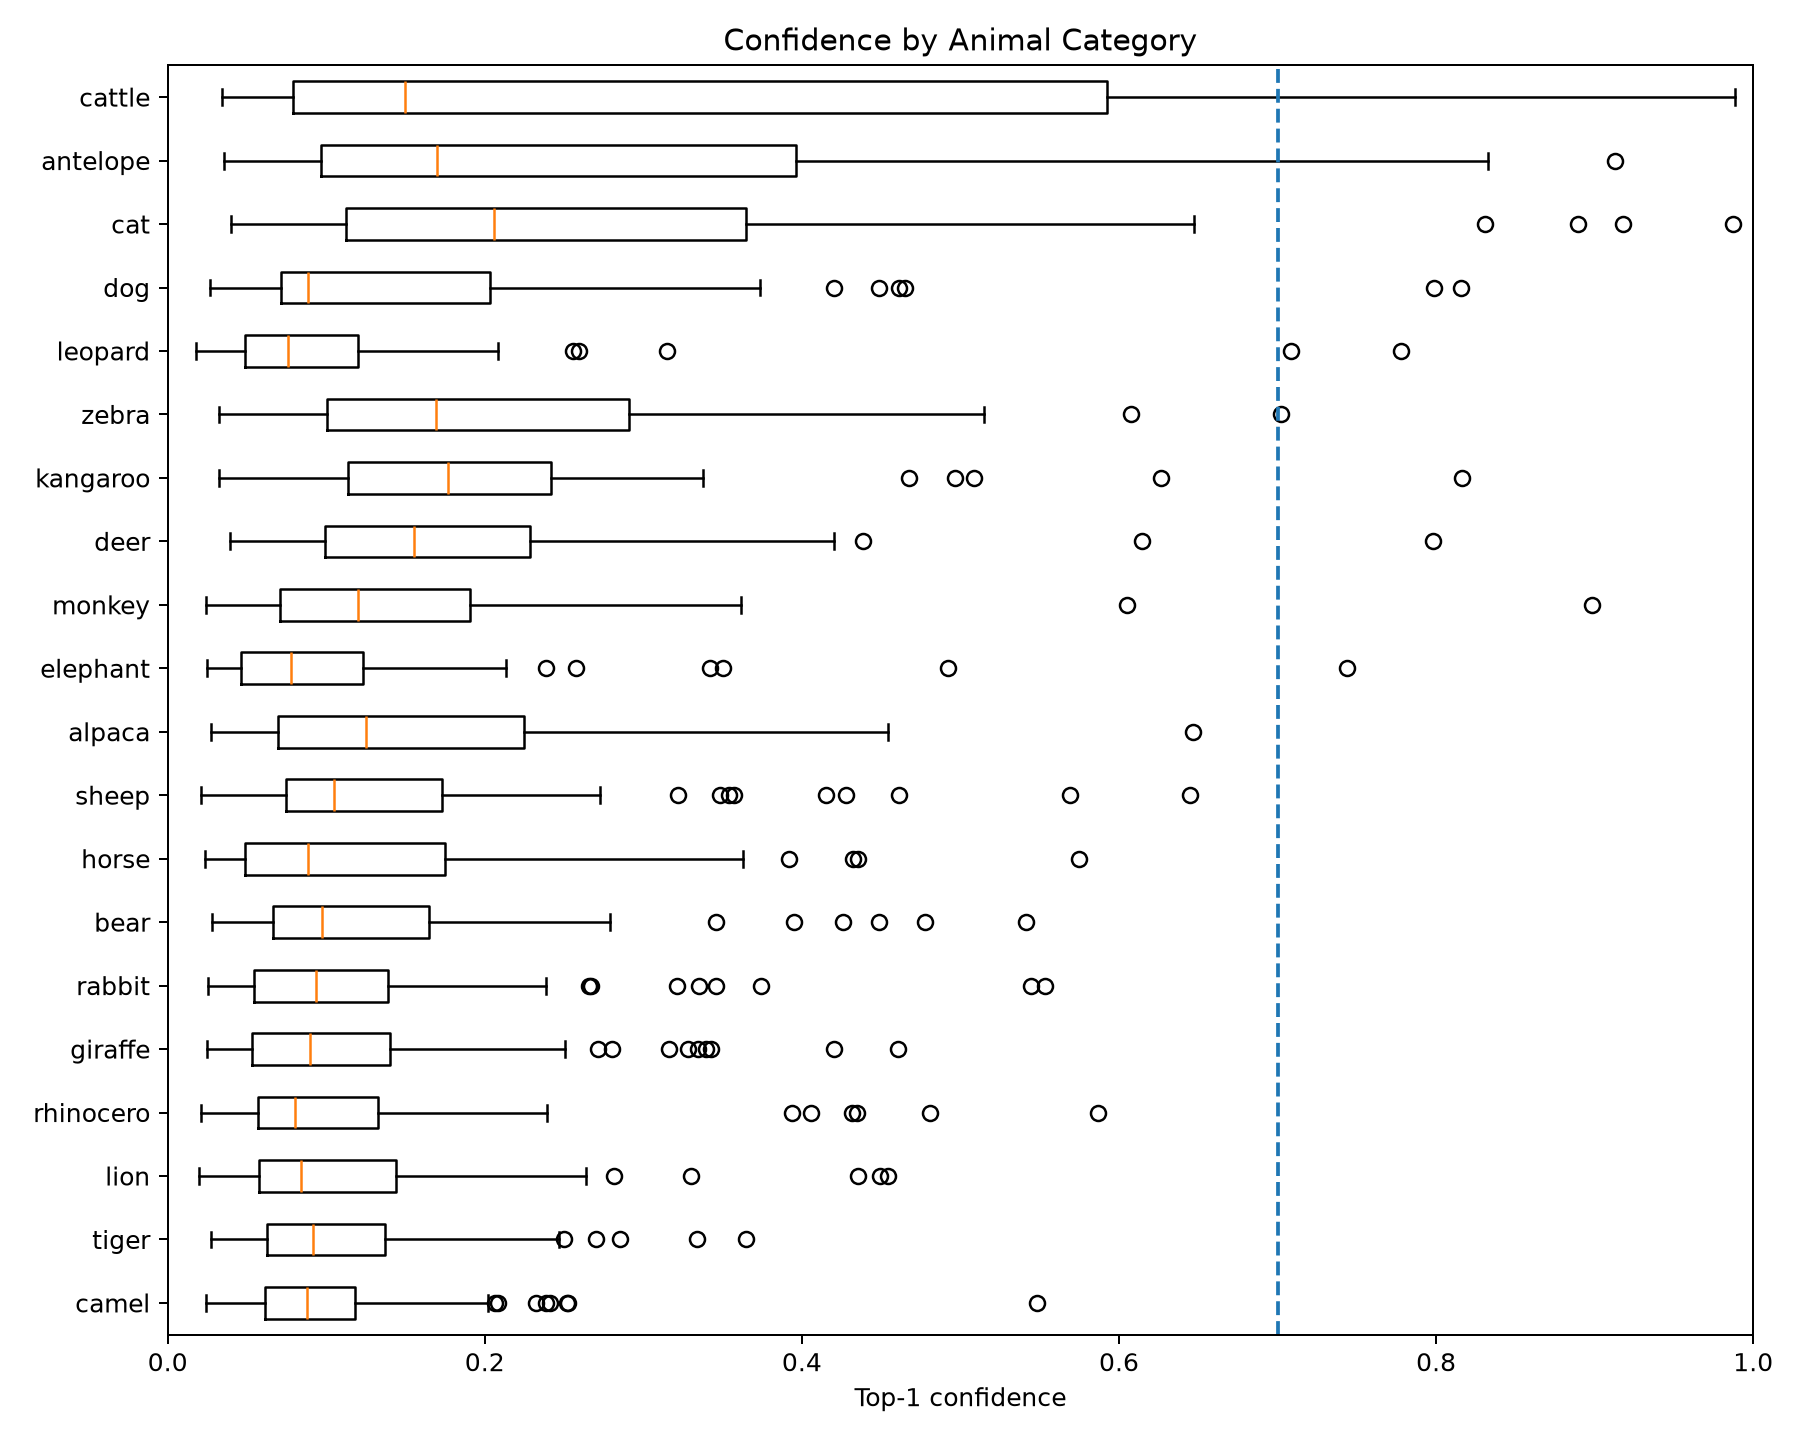

*Figure 4. Box plots of top-1 confidence for each real animal category. Dashed line: 70%.*

**Observation:** The median confidence is low across all 20 animal categories. Yet **cattle, antelope, and cats** have much wider upper ranges and some high-confidence images.

**Interpretation:** Even within cattle, most inputs are *not* highly confident. This suggests the next question is about **which images within a category** trigger high confidence—not simply which category has the highest average.

### 5.2 High-confidence rate by animal category

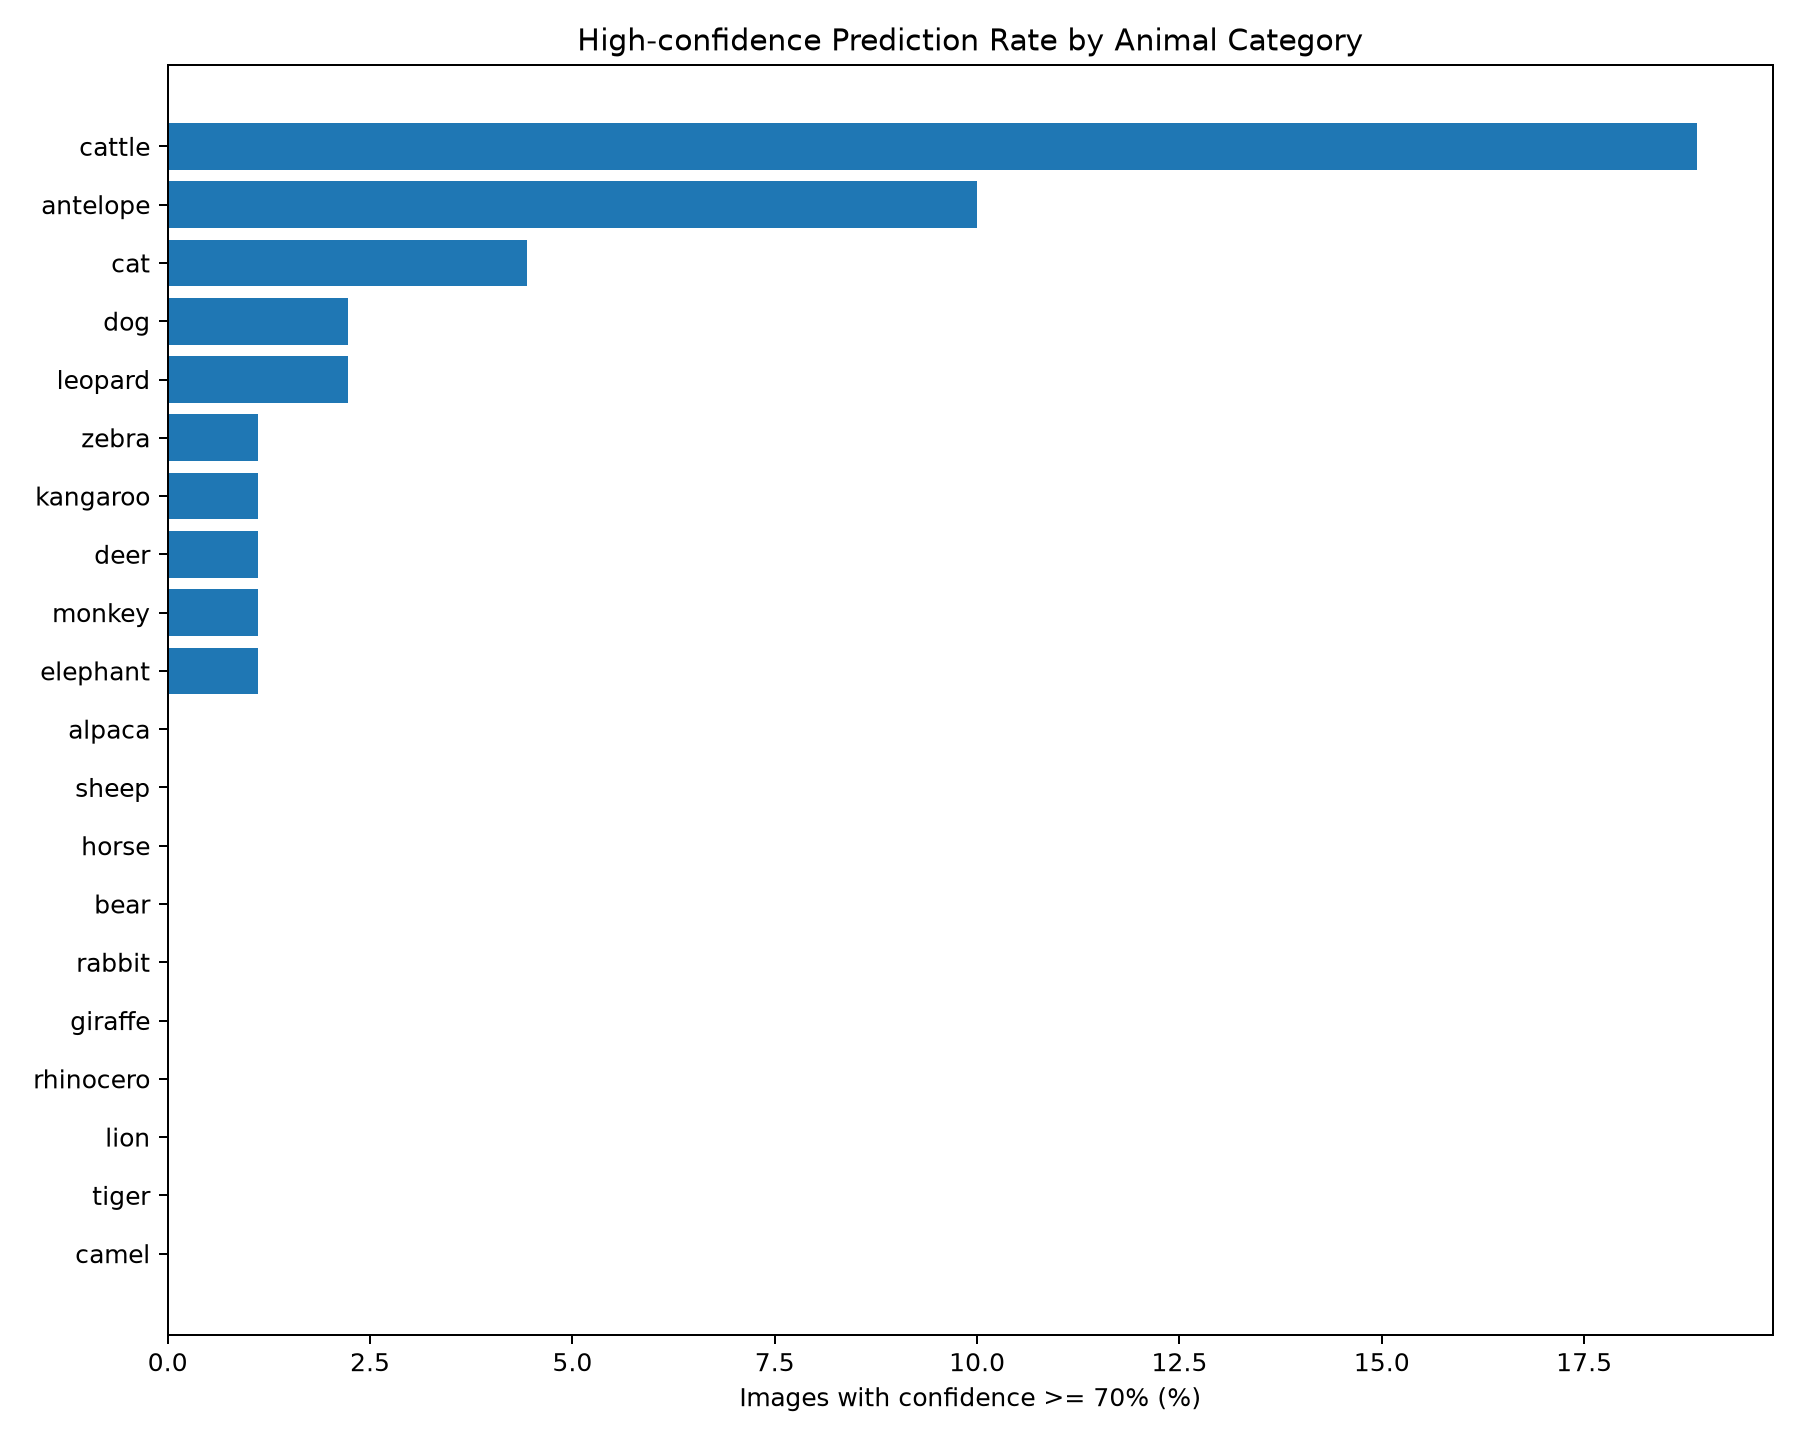

*Figure 5. Percentage of images reaching ≥ 70% top-1 confidence, by animal category.*

The high-confidence results are concentrated in a few categories:

| Animal category | Images ≥ 70% | Approximate rate |
|:---|---:|---:|
| **Cattle** | **17** | **18.9%** |
| **Antelope** | **9** | **10.0%** |
| **Cat** | **4** | **4.4%** |
| Dog | 2 | 2.2% |
| Leopard | 2 | 2.2% |

*Cattle and antelope contribute 26 of the 39 high-confidence images (66.7%). Rates are based on approximately 90 training images per animal category and should be calculated using actual denominators for final reporting.*

## 6. Which Pokémon are predicted with high confidence?

### 6.1 Animal-to-Pokémon prediction matrix (confidence ≥ 70%)

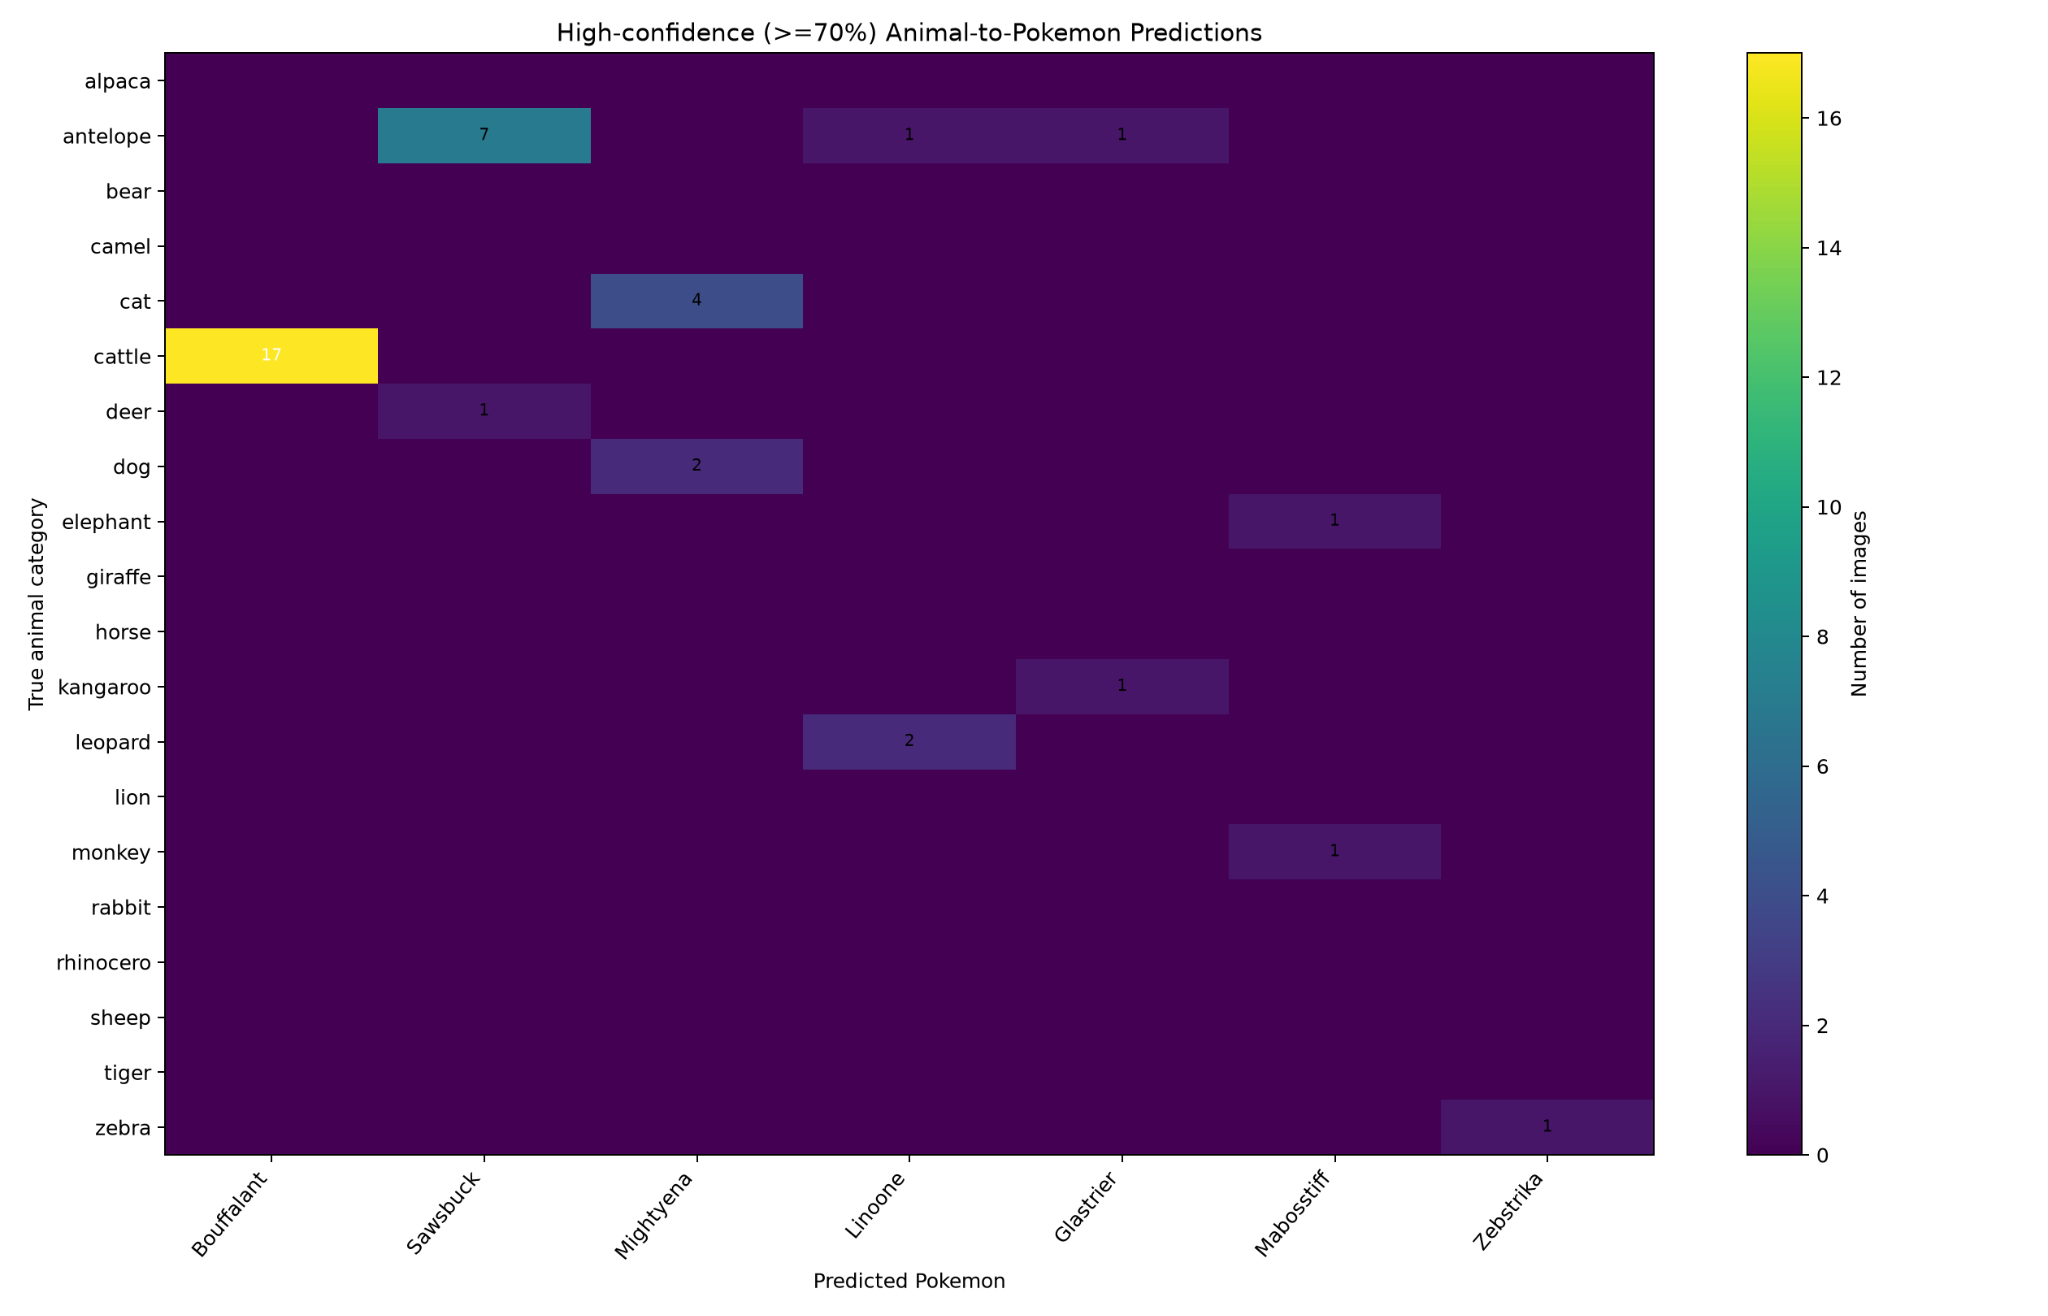

*Figure 6. Counts of high-confidence predictions; rows = real animal category, columns = predicted Pokémon label.*

**Observation:** The 39 high-confidence animal images map to just **7 Pokémon labels**. The strongest pairs are:

| Real animal | Predicted Pokémon | Images |
|:---|:---|---:|
| **Cattle** | **Bouffalant** | **17** |
| **Antelope** | **Sawsbuck** | **7** |
| Cat | Mightyena | 4 |
| Dog | Mightyena | 2 |
| Leopard | Linoone | 2 |
| Antelope | Linoone | 1 |
| Antelope | Mabosstiff | 1 |
| Deer | Sawsbuck | 1 |
| Elephant | Mabosstiff | 1 |
| Kangaroo | Glastrier | 1 |
| Monkey | Mabosstiff | 1 |
| Zebra | Zebstrika | 1 |
| **Total** | | **39** |

Some pairings (e.g., cattle → Bouffalant) **suggest a visual resemblance hypothesis**. Others (e.g., cat → Mightyena) are less obvious. Neither pattern proves what visual features the model used.

## 7. Preliminary interpretation and next steps

### What we can conclude so far

- Most FG animal images receive **low confidence and high entropy**.
- A **small high-confidence tail** exists: **39 of 1,800 images (2.17%)**.
- High-confidence predictions are **not spread evenly across animal categories**; cattle and antelope account for most of them.
- These cases tend to map to **a few specific Pokémon labels**, especially Bouffalant and Sawsbuck.

### What we cannot conclude yet

We have **not established the cause** of these predictions. The effects of animal shape, local texture, framing, category preferences, and FG extraction artifacts remain hypotheses. Also, the classifier has no explicit OOD rejection output.

### Suggested next analysis

1. Compare the **full prediction-frequency matrix** (all confidence levels) with the ≥70% matrix.
2. Compare **high- and low-confidence images within cattle, antelope, and cat** categories.
3. Use **image perturbations and XAI methods** (e.g., occlusion, LIME, ViT-compatible attribution) to test which visual regions affect predictions.

> **Working research question:** Why do some images within the same real-world animal category trigger highly confident Pokémon predictions while most do not?